# Workshop #4 — Dashboard Visual Design, Accessibility & Empty-State Lab
**Course:** Data Analysis Programming (*Programación para Análisis de Datos*) — Semester 2026-II  
**Team 1:** Natural Hazard Monitoring Systems — Earthquake Activity Monitoring  
**Authors:** Juan Córdoba (`20211020097`), Angelo Ibáñez (`20212020007`), Mauricio Sánchez (`20212020045`)

---

## Objective
This notebook serves as the reproducible design studio for both Workshop #4 Dash applications (`dashboard/governance_app.py` on `:8050` and `dashboard/storytelling_app.py` on `:8051`). Rather than duplicating plotting logic, it **imports the exact pure figure builders** from `dashboard/figures_governance.py` and `dashboard/figures_storytelling.py`, justifies every chart type using our course's *Choosing the Right Chart* taxonomy, simulates **Color-Vision Deficiency (CVD)** accessibility, and verifies empty-state resilience.


## 1. Visual Encoding & Chart Selection Rationale (*Choosing the Right Chart*)

| Analytical Goal | Variables & Scale | Selected Encoding | Dashboard Panel | Anti-Pattern Explicitly Rejected |
|---|---|---|---|---|
| Compare skewed frequency vs. physical energy | 5 ordinal classes × 2 % shares | **Grouped Vertical Bar Chart** | Storytelling Panel A (Left) | **5-slice Pie Chart** (`0.003%` micro-seismic energy slice is invisible; area/angle perception is inaccurate) |
| Part-to-whole crustal vs. mantle exposure | 3 depth regimes summing to 100% | **3-Segment Donut with Center KPI** | Storytelling Panel A (Right) | Unordered multi-slice pie (>3 categories) or 3D pie distortion |
| Track multi-week anomaly trajectory vs. policy limits | Daily index + `log10(J)` + 4 alert tiers | **Dual-Axis Line + Shape/Color Scatter + Threshold Lines** | Storytelling Panel B | Color-only status encoding without shape/label redundancy |
| Highlight volumetric earthquake swarms | Daily count + peak annotations | **Stacked Alert Bar Chart with Callouts** | Storytelling Panel C | Unannotated raw point cloud hiding peak magnitudes |
| Rank hotspot localities | Top 15 nominal regions × count + `Mmax` | **Sorted Horizontal Bar Chart** | Storytelling Panel D | Vertical bar chart with rotated/truncated geographic labels |
| Contrast network coverage & temporal windows | 4 networks / 4 cohorts × rate & `Mw` | **Single Toggle Panel (Stacked Bar ↔ Dual-Axis Cohort)** | Storytelling Panel E | Comparing raw unnormalized counts across windows of unequal duration (`1d` vs `38d`) without daily rates & caveats |
| Locate global hazard & subduction depth | Lat, Lon, Magnitude, Depth (km), Tsunami | **Natural Earth `Scattergeo` (`Viridis_r` depth + crimson tsunami halo)** | Storytelling Panel F | Rainbow/Jet colormap (perceptually non-monotonic and inaccessible under CVD) |
| Audit completeness, outliers & text length | 13 fields / 4 numeric / 4 sources vs SLAs | **Horizontal Bars + Log-Projected Quartile Whiskers** | Governance `:8050` | Plotting `energy_joules` (`10^12 J`) on the same linear axis as `magnitude` (`4.6 Mw`), which collapses quartiles to zero |


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.io as pio

# Compact JSON mime output keeps executed notebook lightweight (<500 KB) while preserving full figure specs
pio.renderers.default = "plotly_mimetype"

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from dashboard.gold_loader import load_gold
from dashboard.figures_governance import (
    extract_governance_kpis,
    build_null_rate_fig,
    build_volume_over_time_fig,
    build_outlier_rate_fig,
    build_outlier_quartile_spread_fig,
    build_text_length_fig,
)
from dashboard.figures_storytelling import (
    build_severity_energy_fig,
    build_depth_attenuation_fig,
    build_saai_trend_fig,
    build_daily_volume_swarms_fig,
    build_top_regions_fig,
    build_comparison_panel_fig,
    build_epicenter_map_fig,
)

gov_df = load_gold("governance").df
story_df = load_gold("storytelling").df
print("Loaded curated datasets:", gov_df.shape, story_df.shape)


Loaded curated datasets: (123, 13) (262, 25)


## 2. Production Figure Builders Audit — Governance (`:8050`) & Storytelling (`:8051`)


In [2]:
catalog = [
    ("Gov — Null & 10 km Pinning", build_null_rate_fig(gov_df)),
    ("Gov — Volume Over Time (Daily)", build_volume_over_time_fig(gov_df, view_mode="daily")),
    ("Gov — Volume Over Time (Cumulative)", build_volume_over_time_fig(gov_df, view_mode="cumulative")),
    ("Gov — Tukey IQR Outlier Rate", build_outlier_rate_fig(gov_df)),
    ("Gov — Quartile Spread & Fence", build_outlier_quartile_spread_fig(gov_df)),
    ("Gov — Descriptor Length by Agency", build_text_length_fig(gov_df)),
    ("Story A1 — Magnitude vs Energy Paradox", build_severity_energy_fig(story_df)),
    ("Story A2 — Focal Depth Regimes Donut", build_depth_attenuation_fig(story_df)),
    ("Story B — Daily SAAI & Radiated Energy", build_saai_trend_fig(story_df)),
    ("Story C — Daily Volume & Swarm Peaks", build_daily_volume_swarms_fig(story_df)),
    ("Story D — Top 15 Active Regions", build_top_regions_fig(story_df)),
    ("Story E1 — By Monitoring Network", build_comparison_panel_fig(story_df, mode="agency")),
    ("Story E2 — Historical vs Current Cohorts", build_comparison_panel_fig(story_df, mode="historical_vs_current")),
    ("Story F — Global Significant Epicenters Map", build_epicenter_map_fig(story_df)),
]

audit_rows = []
for name, fig in catalog:
    base_font = int(fig.layout.font.size or 12)
    has_source = any("Source:" in str(a.text) for a in (fig.layout.annotations or []))
    audit_rows.append({
        "Panel": name,
        "Traces": len(fig.data),
        "Base_Font_px": base_font,
        "Height_px": fig.layout.height,
        "Has_Title": bool(fig.layout.title.text),
        "Has_Source_Footer": has_source,
    })
    assert base_font >= 12 and has_source and len(fig.data) >= 1

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

# Render key representative production figures inline (JSON mimetype)
for idx in (0, 6, 8, 13):
    catalog[idx][1].show()


,Panel,Traces,Base_Font_px,Height_px,Has_Title,Has_Source_Footer
0,Gov — Null & 10 km Pinning,2,12,400,True,True
1,Gov — Volume Over Time (Daily),5,12,400,True,True
2,Gov — Volume Over Time (Cumulative),5,12,400,True,True
3,Gov — Tukey IQR Outlier Rate,2,12,360,True,True
4,Gov — Quartile Spread & Fence,8,12,360,True,True
5,Gov — Descriptor Length by Agency,1,12,360,True,True
6,Story A1 — Magnitude vs Energy Paradox,2,12,390,True,True
7,Story A2 — Focal Depth Regimes Donut,1,12,390,True,True
8,Story B — Daily SAAI & Radiated Energy,4,12,410,True,True
9,Story C — Daily Volume & Swarm Peaks,2,12,410,True,True


## 3. Color-Vision Deficiency (CVD) Simulation & WCAG 2.1 Contrast Verification
We test our semantic alert/status palette (`Normal/PASS #1b9e77`, `Elevated/WARN #d95f02`, `High #c0392b`, `Critical #7b0d1e`, `Info #3b6998`) under **Machado et al. (2009)** full dichromacy matrices (**Deuteranopia**, **Protanopia**, **Tritanopia**) and compute WCAG 2.1 contrast ratios against white (`#ffffff`), paired with redundant geometric shapes (`● ▲ ■ ◆`).


,Tier,Redundant_Badge,Hex,Contrast_vs_White
0,NORMAL,● Normal (< 1.0),#1b9e77,3.39
1,ELEVATED,▲ Elevated (1.0–1.99),#d95f02,3.76
2,HIGH,■ High (2.0–3.49),#c0392b,5.44
3,CRITICAL,◆ Critical (≥ 3.5),#7b0d1e,10.95
4,INFO,● Informational,#3b6998,5.74


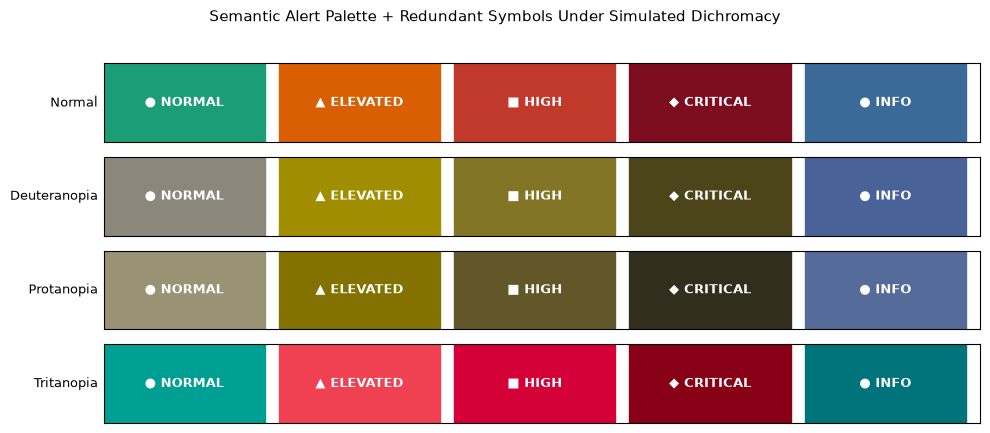

In [3]:
from dashboard.theme import ALERT_COLORS, ALERT_LABELS_WITH_ICON

def hex_to_srgb(h: str) -> np.ndarray:
    h = h.lstrip("#")
    return np.array([int(h[i:i+2], 16) / 255.0 for i in (0, 2, 4)], dtype=float)

def srgb_to_linear(c: np.ndarray) -> np.ndarray:
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(c: np.ndarray) -> np.ndarray:
    c = np.clip(c, 0.0, 1.0)
    return np.where(c <= 0.0031308, 12.92 * c, 1.055 * (c ** (1.0 / 2.4)) - 0.055)

def wcag_contrast_on_white(hex_color: str) -> float:
    lin = srgb_to_linear(hex_to_srgb(hex_color))
    lum = 0.2126 * lin[0] + 0.7152 * lin[1] + 0.0722 * lin[2]
    return (1.0 + 0.05) / (lum + 0.05)

# Standard linear-RGB dichromacy simulation matrices (Viénot / Machado approximations)
CVD_MATRICES = {
    "Normal Trichromacy": np.eye(3),
    "Deuteranopia (M-cone absent)": np.array([
        [0.367322, 0.860646, -0.227968],
        [0.280085, 0.672501,  0.047413],
        [-0.011820, 0.042940, 0.968881],
    ]),
    "Protanopia (L-cone absent)": np.array([
        [0.152286, 1.052583, -0.204868],
        [0.114503, 0.786281,  0.099216],
        [-0.003882, -0.048116, 1.051998],
    ]),
    "Tritanopia (S-cone absent)": np.array([
        [1.255528, -0.076749, -0.178779],
        [-0.078411, 0.930809,  0.147602],
        [0.004733,  0.691367,  0.303900],
    ]),
}

tiers = ["NORMAL", "ELEVATED", "HIGH", "CRITICAL", "INFO"]
contrast_rows = []
for t in tiers:
    hx = ALERT_COLORS[t]
    contrast_rows.append({
        "Tier": t,
        "Redundant_Badge": ALERT_LABELS_WITH_ICON[t],
        "Hex": hx,
        "Contrast_vs_White": round(wcag_contrast_on_white(hx), 2),
    })
display(pd.DataFrame(contrast_rows))

fig, axes = plt.subplots(len(CVD_MATRICES), 1, figsize=(10, 4.2))
for ax, (mode_name, mat) in zip(axes, CVD_MATRICES.items()):
    for idx, t in enumerate(tiers):
        lin = srgb_to_linear(hex_to_srgb(ALERT_COLORS[t]))
        sim_srgb = linear_to_srgb(mat @ lin)
        ax.add_patch(plt.Rectangle((idx, 0), 0.92, 1.0, color=sim_srgb))
        ax.text(idx + 0.46, 0.5, ALERT_LABELS_WITH_ICON[t].split()[0] + " " + t,
                ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    ax.set_xlim(0, len(tiers))
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_ylabel(mode_name.split()[0], fontsize=9, rotation=0, ha="right", va="center")
plt.suptitle("Semantic Alert Palette + Redundant Symbols Under Simulated Dichromacy", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()


## 4. Empty-State & Restrictive-Filter Resilience Verification


In [4]:
empty_df = pd.DataFrame()
empty_checks = [
    ("Gov Null Rate (empty DF)", build_null_rate_fig(empty_df)),
    ("Gov Volume (0 sources selected)", build_volume_over_time_fig(gov_df, selected_sources=[])),
    ("Story SAAI (0 alert tiers selected)", build_saai_trend_fig(story_df, alert_tiers=[])),
    ("Story Epicenter Map (0 networks selected)", build_epicenter_map_fig(story_df, selected_agencies=[])),
    ("Story Comparison (empty DF)", build_comparison_panel_fig(empty_df)),
]
for label, efig in empty_checks:
    ann_texts = [str(a.text) for a in (efig.layout.annotations or [])]
    print(f"[PASS] {label:42s} -> traces={len(efig.data)}, guidance={ann_texts[0]}")
    assert len(efig.data) == 0 and len(ann_texts) >= 2


[PASS] Gov Null Rate (empty DF)                   -> traces=0, guidance=<b>No null-rate metrics available in Gold dataset.</b>
[PASS] Gov Volume (0 sources selected)            -> traces=0, guidance=<b>Select at least one seismic source in the dropdown filter above.</b>
[PASS] Story SAAI (0 alert tiers selected)        -> traces=0, guidance=<b>Select at least one alert posture level in the filter bar above.</b>
[PASS] Story Epicenter Map (0 networks selected)  -> traces=0, guidance=<b>Select at least one monitoring network to display significant epicenters.</b>
[PASS] Story Comparison (empty DF)                -> traces=0, guidance=<b>Comparative network and temporal cohort summaries are unavailable.</b>
